# BasQ Qiskit Fall Fest 2026 | Advanced – Beyond a Single Ansatz

## The challenge

The advanced challenge asks participants to estimate a molecular ground-state energy in a system where a straightforward variational circuit struggles. The brief invites hybrid approaches that sample useful electron configurations from circuits and use classical post-processing to find a better energy.

**Starter notebook**  
Benjamin Tirado wrote *Ground-State Energy of a Molecule with VQE* for Basque Quantum (BasQ). The event was organised by BasQ in collaboration with IBM. The original attribution and licence are included with the starter material below. [BasQ event recap](https://www.basquequantum.eus/en/news/qiskit-fall-fest-2026-brings-together-quantum-community-three-basque-cities)

## My task

**Project extension by Datrim Wadhawan**

I used a simulated quantum circuit to sample ways of arranging electrons in a stretched chain of six hydrogen atoms. I then used a classical eigensolver to estimate the lowest energy available within those sampled configurations. This approach, called **sample-based quantum diagonalisation (SQD)**, brought the estimate much closer to the classical reference than the first optimisation checkpoint and essentially matched a longer optimisation. I also tested whether shallower sampling circuits could retain most of that accuracy with fewer two-qubit gates.

> **Goal**  
> For linear $\mathrm{H}_6$ with 1.50 Å between neighbours, test whether SQD can improve on a one-iteration UCCSD-VQE checkpoint. Compare it with a converged UCCSD-VQE run, two classical selection controls, and shallower circuits at the same total shot budget.

### Key results

**VQE** is the variational quantum eigensolver, which adjusts a trial circuit to minimise its energy. **UCCSD** is unitary coupled cluster with singles and doubles, a trial circuit built from one- and two-electron excitations. A **determinant** is an antisymmetric many-electron basis state specified by which spin orbitals are occupied. **FCI** (full configuration interaction) solves for the energy using the full determinant space of the chosen model. A millihartree (mHa) is $10^{-3}$ Hartree (Ha). A **shot** is one simulated circuit measurement, and a **CNOT** is a controlled-NOT two-qubit gate.

| Method | Gap above singlet FCI (mHa) | Selected determinants | VQE energy evaluations | CNOTs per preparation |
| --- | ---: | ---: | ---: | ---: |
| Early UCCSD-VQE (one optimiser iteration) | 69.25 | — | 236 | 9,672 |
| Converged UCCSD-VQE (12 optimiser iterations) | 4.74 | — | 1,418 | 9,672 |
| Full-circuit SQD (8,192 shots) | 4.72 | 100 | 236 | 9,672 |
| SQD with 48 MP2-ranked excitations (8,192 shots) | 7.07 | 91 | 0 | 4,576 |
| Uniform random control (median of 32 trials) | 785.59 | 100 | — | — |
| Hamiltonian-guided control (matched determinant count) | 8.12 | 100 | — | — |
| Hamiltonian-guided control (matched singlet dimension) | 8.21 | 99 | — | — |

Full-circuit SQD reuses the 236 energy evaluations from the early checkpoint. MP2 (second-order Møller–Plesset perturbation theory) supplies the smaller circuit's angles through a classical calculation. Its zero VQE evaluations leave out that classical work. The CNOT column counts compiled gates per preparation and gives a shot-weighted mean when several circuits are pooled.

### Background

An **ansatz** is a proposed form for the trial state. The UCCSD ansatz starts from a Hartree–Fock state, a one-determinant mean-field approximation, and adds excitation operators. On a stretched chain, several electron configurations can contribute substantially to the true ground state. A fixed circuit can be costly to compile and optimise, and it may still leave residual error after the optimiser converges.

SQD reads circuit measurements as occupation bitstrings and uses the distinct determinants to build a subspace. With $\mathcal S$ denoting the retained determinants, the energy estimate comes from

$$
(H_{\mathcal S})_{ij}=\langle D_i\mid\hat H_{\mathrm{el}}\mid D_j\rangle,
\qquad E_{\mathrm{SQD}}=\lambda_{\min}(H_{\mathcal S})+E_{\mathrm{nuc}}.
$$

Here $\hat H_{\mathrm{el}}$ is the electronic Hamiltonian and $E_{\mathrm{nuc}}$ is the fixed nuclear-repulsion energy. For $\mathrm{H}_6$, the code further projects onto spin singlets, states with total spin $S=0$, before diagonalising. **Configuration recovery** in hardware SQD uses information such as target electron counts and estimated orbital occupations to repair noisy bitstrings. These runs use noiseless statevectors. The full-circuit $\mathrm{H}_6$ sampling cell checks the electron counts, and the spin projection selects singlet combinations of the retained determinants. [IBM Quantum's SQD tutorial](https://quantum.cloud.ibm.com/docs/en/tutorials/sample-based-quantum-diagonalization)

The **active space** is the set of orbitals and electrons treated explicitly. A **frozen core** keeps selected inner orbitals occupied throughout a calculation. The $\mathrm{H}_6$ benchmark treats all six spatial orbitals and six electrons in the minimal STO-3G basis. Its reduced eigensolves select determinants within that same orbital space.

**Chemical accuracy** conventionally means an energy error of about 1 kcal/mol (1.60 mHa). The benchmark uses that threshold against its own STO-3G FCI reference.

## Starter walkthrough | Equilibrium hydrogen molecule

The supplied $\mathrm{H}_2$ tutorial establishes the VQE workflow and checks its energy against exact diagonalisation before the $\mathrm{H}_6$ extension.

# <b>Ground-State Energy of a Molecule with VQE </b>
**Author:** Benjamin Tirado  
**Created for:** BasQ Qiskit Fall Fest 2026 — Basque Quantum (BasQ)

<a id="goal"></a>
<div class="alert alert-block alert-success">
    
<b>Goal of this notebook: </b> Compute the **ground-state energy of the hydrogen molecule ($H_2$)** at its equilibrium bond distance using the **Variational Quantum Eigensolver (VQE)**. We will build the full workflow step by step: describe the molecule, map its electronic structure onto qubits with the **Jordan-Wigner** transformation, prepare a **UCCSD** ansatz on top of a **Hartree-Fock** reference state, and optimize it to approximate the lowest energy. By the end, you will have a working template for the electronic-structure problem that you can extend to other molecules and geometries.
</div>

# <b>Table of Contents</b>

* [Background](#background)
* [Pre-requisites](#prereq)
* [Defining the Molecule](#molecule)
* [Mapping to Qubits: Jordan-Wigner](#mapping)
* [The Ansatz: Hartree-Fock + UCCSD](#ansatz)
* [Running VQE](#vqe)
* [Results and Evaluation](#res)
* [Moving forward](#move)
* [Useful resources](#use)

## <b>Background </b> <a id="background"></a>

One of the most natural applications of a quantum computer is simulating **quantum systems** themselves. In quantum chemistry, a central task is to find the **ground-state energy** of a molecule: the lowest possible energy of its electrons for a fixed arrangement of nuclei. This single number governs much of a molecule's chemistry, from its stability to the shape of its bonds.

Classically, the cost of solving the electronic Schrödinger equation exactly grows extremely fast with the number of electrons, quickly becoming intractable. This is where quantum computers offer a promising route: the state of a molecule can be encoded into qubits, and its energy estimated by preparing trial states and measuring them.

The **Variational Quantum Eigensolver (VQE)** is a hybrid quantum-classical algorithm built for exactly this task. It relies on the **variational principle**, which guarantees that for any trial state $|\psi(\vec{\theta})\rangle$,

$$
E(\vec{\theta}) = \frac{\langle \psi(\vec{\theta}) | \hat{H} | \psi(\vec{\theta}) \rangle}{\langle \psi(\vec{\theta}) | \psi(\vec{\theta}) \rangle} \;\geq\; E_0,
$$

where $\hat{H}$ is the molecular Hamiltonian and $E_0$ is the true ground-state energy. In other words, no trial state can ever give an energy *below* the ground state. VQE exploits this by parameterizing the trial state with a quantum circuit (the **ansatz**) and using a **classical optimizer** to tune the parameters $\vec{\theta}$ until the measured energy is as low as possible.

This idea underpins one of IBM Quantum's landmark demonstrations, *Hardware-efficient variational quantum eigensolver for small molecules and quantum magnets* (Kandala et al., Nature, 2017), which computed ground-state energies of small molecules on real superconducting hardware. In this tutorial we take the same conceptual workflow but keep it deliberately simple, working with H$_2$ on a simulator so that each ingredient is easy to inspect.

# <b>Pre-requisites </b> <a id="prereq"></a>
For starters, make sure you have installed the Qiskit SDK and its supporting modules: `qiskit_aer` (for noiseless simulations) and `qiskit_ibm_runtime` (for real-hardware experiments), as well as the visualization package `qiskit[visualization]`. For the chemistry-specific parts we use `qiskit_nature`, which builds the molecular problem and the fermion-to-qubit mappings, together with the classical chemistry backend `pyscf` that computes the one- and two-electron integrals. We also use `qiskit_algorithms` for the VQE routine and its optimizers.

> **Note:** `qiskit_nature` needs a classical electronic-structure driver to obtain the molecular integrals. Here we use PySCF via `PySCFDriver`. On some systems (e.g. native Windows) PySCF can be tricky to install; if so, running inside WSL or a Linux/macOS environment is the smoothest option.

### Set up the notebook environment

The starter's install cell lists the packages for molecular modelling, circuit construction, and visualisation. The square brackets in `qiskit[visualization]` request an optional dependency group.

In [1]:
 %pip install qiskit qiskit_aer qiskit_ibm_runtime qiskit[visualization] qiskit_nature pyscf qiskit_algorithms

zsh:1: no matches found: qiskit[visualization]
Note: you may need to restart the kernel to use updated packages.


The saved log shows that “zsh” rejected the unquoted extra in the original install command. For this repository, follow the pinned setup in the [README](README.md), select that environment as the notebook kernel, and start with the imports below.

### Import the molecular and variational tools

PySCF builds the molecular problem. Qiskit Nature maps it to qubits and constructs the trial circuit, and Qiskit Algorithms compares variational and exact energies.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Keep the chemistry driver, mapping and ansatz in the same convention.
from qiskit_nature.units import DistanceUnit
from qiskit_nature.second_q.drivers import PySCFDriver
from qiskit_nature.second_q.mappers import JordanWignerMapper
from qiskit_nature.second_q.circuit.library import UCCSD, HartreeFock

# Use two solvers so the small variational result can be checked exactly.
from qiskit_algorithms import VQE, NumPyMinimumEigensolver
from qiskit_algorithms.optimizers import SLSQP
from qiskit.primitives import StatevectorEstimator

# <b>Defining the Molecule </b> <a id="molecule"></a>
The first step is to describe the physical system. A molecule is specified by the positions of its nuclei, its total charge, and its spin. For H$_2$ we place two hydrogen atoms along the $z$-axis, separated by their **equilibrium bond distance** of about $0.735$ Å, the separation at which the molecule is most stable.

We also choose a **basis set**, which defines the set of atomic orbitals used to represent the electrons. Here we use the minimal `sto3g` basis: with two hydrogen atoms it gives two spatial orbitals, i.e. four spin-orbitals, and therefore a small problem that is perfect for a first VQE.

The `PySCFDriver` runs a classical Hartree-Fock calculation behind the scenes and hands back an `ElectronicStructureProblem`. This object contains the **second-quantized Hamiltonian**

$$
\hat{H} = \sum_{pq} h_{pq}\, a_p^\dagger a_q + \tfrac{1}{2}\sum_{pqrs} h_{pqrs}\, a_p^\dagger a_q^\dagger a_r a_s,
$$

where the coefficients $h_{pq}$ and $h_{pqrs}$ are the one- and two-electron integrals computed from the chosen geometry and basis, and $a_p^\dagger$, $a_q$ are fermionic creation and annihilation operators.

### Build the $\mathrm{H}_2$ Hamiltonian

I use the starter's neutral molecule at 0.735 Å as a small check on the workflow. The driver reports the number of orbitals, the electron counts for the two spin labels $\alpha$ and $\beta$, and the fixed nuclear-repulsion term needed for total energies.

In [3]:
driver = PySCFDriver(
    atom="H 0 0 0; H 0 0 0.735",
    basis="sto3g",
    charge=0,
    spin=0,
    # Use Å so the geometry matches the stated bond length.
    unit=DistanceUnit.ANGSTROM,
)

problem = driver.run()

print("Number of spatial orbitals:", problem.num_spatial_orbitals)
print("Number of particles (alpha, beta):", problem.num_particles)
print("Nuclear repulsion energy:", problem.nuclear_repulsion_energy)

Number of spatial orbitals: 2
Number of particles (alpha, beta): (1, 1)
Nuclear repulsion energy: 0.7199689944489797


The driver reports two spatial orbitals and one electron of each spin label. The nuclear repulsion is 0.719969 Ha at this geometry and is added to the electronic energy when reporting the total.

# <b>Mapping to Qubits: Jordan-Wigner </b> <a id="mapping"></a>
The Hamiltonian above is written in terms of **fermionic** operators, but a quantum computer works with **qubits**. We therefore need a *fermion-to-qubit mapping* that translates fermionic creation/annihilation operators into Pauli operators ($X$, $Y$, $Z$, $I$) acting on qubits, while preserving the anticommutation relations that make electrons behave like electrons.

The **Jordan-Wigner** transformation is the most direct such mapping: it assigns **one qubit per spin-orbital**, so the state $|1\rangle$ means "this spin-orbital is occupied" and $|0\rangle$ means "empty". For our H$_2$ problem in the `sto3g` basis, four spin-orbitals map onto **four qubits**.

Applying the mapper turns the fermionic Hamiltonian into a weighted sum of Pauli strings,

$$
\hat{H} = \sum_j c_j \, \hat{P}_j, \qquad \hat{P}_j \in \{I, X, Y, Z\}^{\otimes n},
$$

which is exactly the form whose expectation value a quantum computer can estimate.

### Encode orbital occupations on qubits

The Jordan–Wigner mapping represents each spin orbital by one qubit and writes the electronic Hamiltonian as a sum of Pauli operators. This gives the estimator and the later sampled-subspace calculation a common energy operator.

In [4]:
# Keep an occupation-based encoding so samples can identify determinants.
mapper = JordanWignerMapper()

# The fermionic Hamiltonian ("second-quantized operator") for this problem:
fermionic_op = problem.hamiltonian.second_q_op()

# Map it to a qubit (Pauli) operator:
qubit_op = mapper.map(fermionic_op)

print("Number of qubits:", qubit_op.num_qubits)
print("Number of Pauli terms:", len(qubit_op))
print(qubit_op)

Number of qubits: 4
Number of Pauli terms: 15
SparsePauliOp(['IIII', 'IIIZ', 'IIZI', 'IZII', 'ZIII', 'IIZZ', 'IZIZ', 'ZIIZ', 'YYYY', 'XXYY', 'YYXX', 'XXXX', 'IZZI', 'ZIZI', 'ZZII'],
              coeffs=[-0.81054798+0.j,  0.17218393+0.j, -0.22575349+0.j,  0.17218393+0.j,
 -0.22575349+0.j,  0.12091263+0.j,  0.16892754+0.j,  0.16614543+0.j,
  0.0452328 +0.j,  0.0452328 +0.j,  0.0452328 +0.j,  0.0452328 +0.j,
  0.16614543+0.j,  0.17464343+0.j,  0.12091263+0.j])


The mapped Hamiltonian has four qubits and 15 Pauli terms, including the identity term. Each measurement bit can now be read as an occupation of a spin orbital.

# <b>The Ansatz: Hartree-Fock + UCCSD </b> <a id="ansatz"></a>
VQE needs a **parameterized trial state**, the ansatz. A good ansatz should be expressive enough to reach the true ground state, yet not so large that the optimizer gets lost. For chemistry, a physically motivated and widely used choice is the **Unitary Coupled Cluster with Singles and Doubles (UCCSD)** ansatz.

The idea is to start from a good, cheap approximation and improve it:

- **Hartree-Fock (HF) reference state.** This is the mean-field solution, where each electron occupies the lowest available spin-orbitals. On qubits it is simply the computational basis state with the occupied orbitals set to $|1\rangle$. It is our starting point.
- **UCCSD excitations.** On top of HF, UCCSD applies parameterized *single* and *double* excitations, which move electrons from occupied into virtual (empty) orbitals. Formally the trial state is

$$
|\psi(\vec{\theta})\rangle = e^{\hat{T}(\vec{\theta}) - \hat{T}^\dagger(\vec{\theta})} \, |\text{HF}\rangle,
$$

where $\hat{T}$ collects the single and double excitation operators and $\vec{\theta}$ are the parameters VQE will optimize. Capturing these excitations is what lets the ansatz describe **electron correlation** — the physics that Hartree-Fock alone misses.

In Qiskit Nature, `UCCSD` builds this circuit for us, and we pass it a `HartreeFock` object as its `initial_state`.

### Prepare the $\mathrm{H}_2$ trial circuit

Build the Hartree–Fock reference and add the UCCSD excitation circuit. The circuit drawing shows the decomposition used to inspect the three adjustable parameters.

Number of qubits: 4
Number of variational parameters: 3


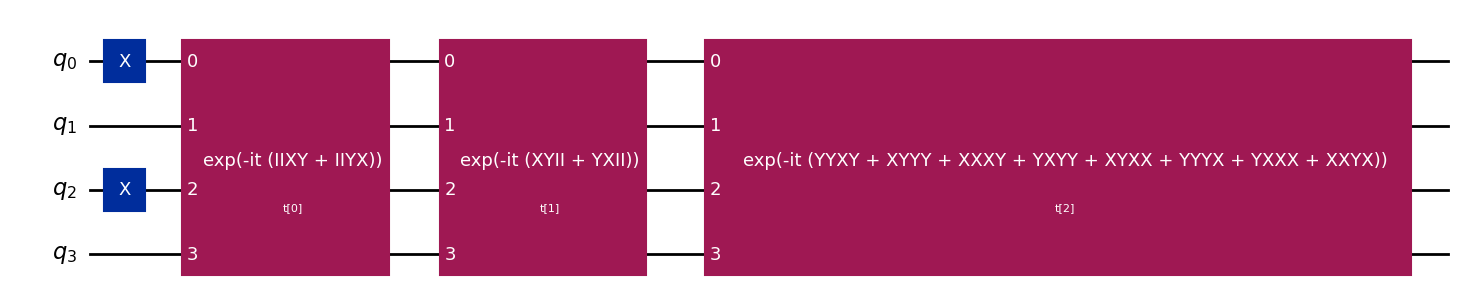

In [5]:
hf_state = HartreeFock(
    problem.num_spatial_orbitals,
    problem.num_particles,
    mapper,
)

ansatz = UCCSD(
    problem.num_spatial_orbitals,
    problem.num_particles,
    mapper,
    # Start from occupied mean-field orbitals before applying excitations.
    initial_state=hf_state,
)

print("Number of qubits:", ansatz.num_qubits)
print("Number of variational parameters:", ansatz.num_parameters)
ansatz.decompose().draw("mpl", fold=-1)

The circuit has four qubits and three variational parameters. The diagram shows the gate decomposition that implements those adjustable excitations from the Hartree–Fock reference.

# <b>Running VQE </b> <a id="vqe"></a>
We now have every ingredient VQE needs:

1. An **Estimator primitive**, which evaluates the expectation value $\langle \psi(\vec{\theta}) | \hat{H} | \psi(\vec{\theta})\rangle$. Here we use the `StatevectorEstimator`, an exact, noiseless simulator that is ideal for understanding the algorithm before moving to hardware.
2. The **ansatz**, our UCCSD + Hartree-Fock trial state.
3. A **classical optimizer**, which proposes new parameters to lower the energy. We use `SLSQP`, a gradient-based optimizer that works well for smooth, low-dimensional problems like this one.

A natural starting point for the parameters is all zeros: this corresponds to applying no excitations, so the trial state is exactly the Hartree-Fock state. The optimizer then explores from there. Because our system is tiny, we can also compute the **exact** ground-state energy with a classical eigensolver (`NumPyMinimumEigensolver`) and use it to check the VQE result.

The `GroundStateEigensolver` from Qiskit Nature conveniently ties the mapper and the solver together and, importantly, **adds back the nuclear repulsion energy** so that the number we get out is the total molecular energy.

### Check VQE against exact diagonalisation

Use a noiseless statevector to evaluate each trial circuit while the SLSQP optimiser adjusts the angles. Starting all angles at zero makes the first trial state Hartree–Fock. The comparison uses total energies for both solvers.

In [6]:
from qiskit_nature.second_q.algorithms import GroundStateEigensolver

#  Exact classical reference
numpy_solver = NumPyMinimumEigensolver()
exact_calc = GroundStateEigensolver(mapper, numpy_solver)
exact_result = exact_calc.solve(problem)
# Use the total energy so the nuclear term is included for both solvers.
exact_energy = exact_result.total_energies[0]

# VQE
estimator = StatevectorEstimator()
optimizer = SLSQP()

vqe = VQE(estimator, ansatz, optimizer)
# Zero angles make the first trial state the Hartree–Fock reference.
vqe.initial_point = np.zeros(ansatz.num_parameters)

vqe_calc = GroundStateEigensolver(mapper, vqe)
vqe_result = vqe_calc.solve(problem)
vqe_energy = vqe_result.total_energies[0]

print(f"Exact ground-state energy : {exact_energy:.6f} Ha")
print(f"VQE  ground-state energy  : {vqe_energy:.6f} Ha")
print(f"Absolute error            : {abs(vqe_energy - exact_energy):.2e} Ha")

Exact ground-state energy : -1.137306 Ha
VQE  ground-state energy  : -1.137306 Ha
Absolute error            : 5.78e-11 Ha


scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


Exact diagonalisation and VQE both give −1.137306 Ha at the displayed precision. Their absolute difference of $5.78\times10^{-11}$ Ha is well below 1.60 mHa. The saved SciPy messages concern sparse matrix storage formats.

# <b>Results and Evaluation </b> <a id="res"></a>
If everything went well, the VQE energy should agree with the exact diagonalization to well within **chemical accuracy**, usually defined as $1.6 \times 10^{-3}$ Hartree ($\approx 1$ kcal/mol). This is the precision threshold chemists care about, because it is roughly the accuracy needed to predict reaction energies reliably.

The comparison below shows the VQE energy against the exact value. On a noiseless simulator with the UCCSD ansatz, the two should sit essentially on top of each other, confirming that our ansatz is expressive enough to capture the ground state of H$_2$. The Hartree-Fock energy is included as a baseline so you can *see* how much energy the correlation captured by UCCSD recovers.

### Compare with the Hartree–Fock reference

Evaluate the Hamiltonian on the Hartree–Fock state and add nuclear repulsion so it can be compared directly with the exact and VQE total energies. The difference between the Hartree–Fock and VQE bars measures the energy lowering from the trial circuit.

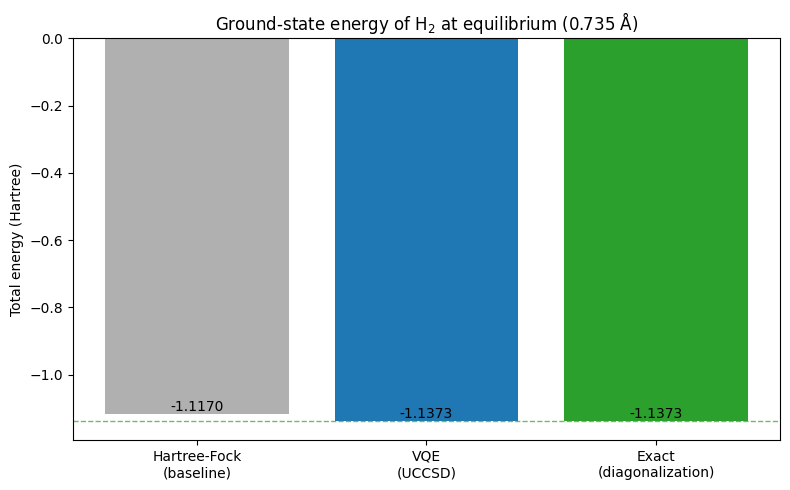

Correlation energy recovered by VQE: 0.020307 Ha


In [7]:
# Hartree-Fock total energy: evaluate the mapped Hamiltonian on the HF state.
# (This is the mean-field baseline, before adding UCCSD correlation.)
from qiskit.primitives import StatevectorEstimator

hf_circuit = HartreeFock(problem.num_spatial_orbitals, problem.num_particles, mapper)
_est = StatevectorEstimator()
_elec_hf = _est.run([(hf_circuit, qubit_op)]).result()[0].data.evs
# Add the same nuclear term included in the VQE and exact totals.
hf_energy = float(_elec_hf) + problem.nuclear_repulsion_energy

labels = ["Hartree-Fock\n(baseline)", "VQE\n(UCCSD)", "Exact\n(diagonalization)"]
energies = [hf_energy, vqe_energy, exact_energy]

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, energies, color=["#B0B0B0", "#1f77b4", "#2ca02c"])
plt.ylabel("Total energy (Hartree)")
plt.title("Ground-state energy of H$_2$ at equilibrium (0.735 \u00c5)")
plt.axhline(exact_energy, color="#2ca02c", ls="--", lw=1, alpha=0.7)

for bar, e in zip(bars, energies):
    plt.text(bar.get_x() + bar.get_width()/2, e, f"{e:.4f}",
             ha="center", va="bottom", fontsize=10)

plt.tight_layout()
plt.show()

print(f"Correlation energy recovered by VQE: {hf_energy - vqe_energy:.6f} Ha")

The VQE and exact results overlap at the plot's precision. VQE lowers the Hartree–Fock energy by 0.020307 Ha for this equilibrium geometry.

# <b>Moving forward </b> <a id="move"></a>
The workflow in this notebook — describe the molecule, map to qubits, choose an ansatz, run VQE — is intentionally minimal. We computed a **single point**: the ground-state energy of H$_2$ at one fixed bond distance, on a noiseless simulator, with a textbook ansatz and mapping. Real chemistry problems ask for more, and that is where the hackathon challenge begins.

The three levels below are deliberately open-ended. They tell you *what* to aim for, not *how* to get there: choosing the geometry, ansatz, mapping, optimizer, and hardware strategy is part of the challenge. Each level builds naturally on the one before.

### <b>Beginner — a potential energy surface</b>
A single energy tells us little; the interesting physics lives in how the energy *changes* with geometry. Your goal is to compute the **potential energy surface (PES)** of the **HeH$^+$ molecular ion** — its total ground-state energy as a function of the bond distance between He and H. Sweep the internuclear distance across a range, run the ground-state calculation at each point, and plot the resulting curve. Can you locate the equilibrium bond length (the minimum of the curve) and estimate the dissociation behaviour as the atoms are pulled apart? Think about what changes as you move away from equilibrium, and whether your chosen ansatz stays accurate everywhere along the curve.

### <b>Intermediate — do more with less</b>
UCCSD on a full spin-orbital mapping is accurate but expensive, and the cost grows quickly with system size. Move to a **larger molecule** (for example LiH or BeH$_2$) and confront the problem of **reducing the quantum resources** needed to reach chemical accuracy: fewer qubits, shorter circuits, or fewer measurements. There are several levers to explore — alternative fermion-to-qubit mappings, exploiting molecular symmetries to taper qubits away, freezing core orbitals, or grouping commuting measurements — and part of the challenge is deciding which combination buys you the most under a fixed budget of shots or circuit depth.

### <b>Advanced — beyond a single ansatz</b>
The expressiveness of a fixed ansatz eventually becomes a bottleneck: for larger or more strongly correlated systems, a single variational circuit may not reach the ground state, or may become untrainable. Explore approaches that **let classical post-processing shoulder more of the load** — for instance, sampling electronic configurations from quantum circuits and diagonalizing within the sampled subspace, or other hybrid quantum-classical strategies that trade a hard-to-optimize deep circuit for many shallower ones. Push toward a system where a naive UCCSD run struggles, and show that your approach does better. What is the largest or most correlated system you can treat while keeping the results trustworthy?



# <b>Useful resources </b> <a id="use"></a>

The following resources may be useful when extending this introductory VQE example toward the full challenge.

### <b>Qiskit Nature (quantum chemistry) </b>

- [Qiskit Nature documentation](https://qiskit-community.github.io/qiskit-nature/)  
  Entry point for building electronic-structure problems, drivers, mappers, and chemistry ansätze.

- [Ground-state solvers tutorial](https://qiskit-community.github.io/qiskit-nature/tutorials/03_ground_state_solvers.html)  
  Step-by-step tutorial on finding molecular ground states with VQE and classical solvers — the closest reference to this notebook.

- [Electronic structure problem tutorial](https://qiskit-community.github.io/qiskit-nature/tutorials/01_electronic_structure.html)  
  Explains drivers, basis sets, and how the second-quantized Hamiltonian is constructed.

- [Qubit mappers tutorial](https://qiskit-community.github.io/qiskit-nature/tutorials/06_qubit_mappers.html)  
  Compares Jordan-Wigner, parity, and Bravyi-Kitaev mappings, including qubit tapering via symmetries — directly relevant to the intermediate challenge.

- [UCCSD ansatz documentation](https://qiskit-community.github.io/qiskit-nature/stubs/qiskit_nature.second_q.circuit.library.UCCSD.html)  
  Reference page for the UCCSD variational form used in this notebook.

### <b>Variational algorithms and optimizers </b>

- [VQE documentation](https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.VQE.html)  
  Reference page for the Variational Quantum Eigensolver class.

- [Qiskit Algorithms optimizers](https://qiskit-community.github.io/qiskit-algorithms/apidocs/qiskit_algorithms.optimizers.html)  
  Reference page for classical optimizers such as `SLSQP`, `COBYLA`, `SPSA`, and others to experiment with.

- [AdaptVQE how-to](https://qiskit-community.github.io/qiskit-nature/howtos/adapt_vqe.html)  
  Builds an ansatz adaptively, a useful stepping stone toward the advanced challenge.

- [Variational quantum algorithms course](https://quantum.cloud.ibm.com/learning/en/courses/utility-scale-quantum-computing/variational-quantum-algorithms)  
  IBM Quantum learning material on the broader family of hybrid variational algorithms.

### <b>Hardware execution, transpilation, and error mitigation </b>

- [Qiskit documentation](https://quantum.cloud.ibm.com/docs/guides/tools-intro)  
  General entry point for circuits, primitives, transpilation, and runtime execution on IBM Quantum.

- [Transpile with pass managers](https://quantum.cloud.ibm.com/docs/guides/transpile-with-pass-managers)  
  How to transpile circuits for a specific backend and its connectivity.

- [Error mitigation and suppression techniques](https://quantum.cloud.ibm.com/docs/guides/error-mitigation-and-suppression-techniques)  
  Overview of the resilience options available through Qiskit Runtime.

- [Combine error mitigation options with the Estimator primitive](https://quantum.cloud.ibm.com/docs/tutorials/combine-error-mitigation-techniques)  
  Tutorial on dynamical decoupling, measurement-error mitigation, gate twirling, and zero-noise extrapolation.

### <b>Background reading </b>

- [Kandala et al., *Hardware-efficient variational quantum eigensolver for small molecules and quantum magnets*, Nature (2017)](https://www.nature.com/articles/nature23879)  
  The IBM Quantum paper that inspires this challenge track.

## <b>Credits and license</b>

This notebook was written by **Benjamin Tirado** for the **BasQ Qiskit Fall Fest 2026**, organised by Basque Quantum (BasQ).

© 2026 Benjamin Tirado. The text, figures and explanations are released under
[CC BY 4.0](https://creativecommons.org/licenses/by/4.0/); the code is released under the
[Apache License 2.0](https://www.apache.org/licenses/LICENSE-2.0), the same license as Qiskit.

You are welcome to run, adapt and share this material — including as a starting point for your own
challenge submission — provided the attribution above is kept. If you reuse it publicly, please cite it as:

> B. Tirado, *Ground-State Energy of a Molecule with VQE*, tutorial notebook, BasQ Qiskit Fall Fest, 2026.

Built with [Qiskit](https://www.ibm.com/quantum/qiskit), [Qiskit Nature](https://qiskit-community.github.io/qiskit-nature/)
and [PySCF](https://pyscf.org/), which remain the property of their respective authors and are used
under their own licenses.

*Questions, corrections or suggestions:* benjamin.tirado@ehu.eus

## My solution | From $\mathrm{H}_2$ to a stretched $\mathrm{H}_6$ chain

I first check the sampled-subspace method on the starter molecule. I then use the same occupation encoding for the larger system, where an early VQE checkpoint leaves more room for improvement.

# <b>Sampling the VQE State </b> <a id="sample-vqe"></a>

We sample the optimised VQE circuit to find which electron configurations
appear. Each distinct bitstring selects a row and column of the Hamiltonian.
We then find the lowest energy in that smaller matrix.

$$
(H_{\mathrm{sub}})_{ij}=\langle D_i|\hat H|D_j\rangle.
$$

### Check the SQD calculation on $\mathrm{H}_2$

Take 512 measurements from the optimised, noiseless circuit and keep each observed determinant once. The sample frequencies determine which determinants are likely to appear, while the projected eigensolver determines their coefficients freely.

In [8]:
from qiskit.quantum_info import Statevector

# Sample the circuit we already trained 
circuit = ansatz.assign_parameters(vqe_result.raw_result.optimal_parameters)
state = Statevector.from_instruction(circuit)
# Fix the sampling draw so the 512-shot check is reproducible.
state.seed(32)
counts = state.sample_counts(512)

# Diagonalise in the sampled configurations
indices = sorted(int(bits, 2) for bits in counts)
hamiltonian = qubit_op.to_matrix()
# Let the eigensolver choose amplitudes within the sampled basis.
projected = hamiltonian[np.ix_(indices, indices)]
sqd_energy = np.linalg.eigvalsh(projected)[0] + problem.nuclear_repulsion_energy

print(f"Distinct configurations: {len(indices)}")
print(f"VQE total energy: {vqe_result.total_energies[0]:.6f} Ha")
print(f"Sampled-subspace energy: {sqd_energy:.6f} Ha")

Distinct configurations: 2
VQE total energy: -1.137306 Ha
Sampled-subspace energy: -1.137306 Ha


The 512 shots yield two distinct determinants. Their subspace gives −1.137306 Ha, the same as the optimised VQE result to six decimal places. This checks the sampling and projection on the small starter example.

# <b>Defining the Hydrogen Chain </b> <a id="hydrogen-chain"></a>

We extend the starter from two hydrogen atoms to six, using the same STO-3G
basis and Jordan–Wigner mapping. Each atom contributes one spatial orbital
and one electron. With three alpha and three beta electrons, the fixed-electron
space contains

$$
D=\binom{6}{3}\binom{6}{3}=400
$$

determinants. We use **full configuration interaction (FCI)** to find the
ground-state energy in this basis, targeting total spin $S=0$. This gives us
a reference for the later UCCSD and sampled-subspace calculations.

### Define the $\mathrm{H}_6$ reference

Place six neutral hydrogen atoms in a line at 1.50 Å intervals. Compare the two Hartree–Fock energies first to check that PySCF and Qiskit describe the same model. Keep electron count and spin consistent when using the singlet FCI energy as the benchmark.

In [9]:
from math import comb

import numpy as np
from pyscf import fci, gto, scf

# Build the H6 Hamiltonian using the starter's workflow
h6_spacing = 1.50
# Use the same minimal basis as the starter to isolate the change in system.
h6_basis = "sto3g"
h6_atoms = "; ".join(f"H 0 0 {i * h6_spacing:.6f}" for i in range(6))

h6_problem = PySCFDriver(
    atom=h6_atoms, basis=h6_basis, charge=0, spin=0,
    unit=DistanceUnit.ANGSTROM,
).run()
h6_mapper = JordanWignerMapper()
h6_qubit_op = h6_mapper.map(h6_problem.hamiltonian.second_q_op())

# Exact classical reference
h6_mol = gto.M(
    atom=h6_atoms, basis=h6_basis, charge=0, spin=0,
    unit="Angstrom", verbose=0,
)
h6_hf = scf.RHF(h6_mol).run()

if not h6_hf.converged:
    raise RuntimeError("H6 Hartree–Fock did not converge.")

# Check both code paths agree before treating FCI as the benchmark.
if not np.isclose(h6_hf.e_tot, h6_problem.reference_energy, rtol=0, atol=1e-7):
    raise RuntimeError("PySCF and Qiskit disagree on the Hartree–Fock energy.")

# Target total spin zero for comparison with the projected sampled estimates.
h6_fci = fci.FCI(h6_hf, singlet=True)
h6_exact_energy, h6_ci_vector = h6_fci.kernel()

if not h6_fci.converged:
    raise RuntimeError("H6 FCI did not converge.")

h6_norb = h6_problem.num_spatial_orbitals
n_alpha, n_beta = h6_problem.num_particles
h6_dimension = comb(h6_norb, n_alpha) * comb(h6_norb, n_beta)
h6_spin_squared, _ = h6_fci.spin_square(
    h6_ci_vector, h6_norb, (n_alpha, n_beta)
)

print(f"H6 spacing: {h6_spacing:.2f} Å")
print(f"Qubits: {h6_qubit_op.num_qubits} | Electron counts: {(n_alpha, n_beta)}")
print(f"Fixed-electron determinant count: {h6_dimension}")
print(f"Hartree–Fock total energy: {h6_hf.e_tot:.6f} Ha")
print(f"FCI total energy: {h6_exact_energy:.6f} Ha")
print(f"FCI <S^2>: {h6_spin_squared:.2e}")

H6 spacing: 1.50 Å
Qubits: 12 | Electron counts: (3, 3)
Fixed-electron determinant count: 400
Hartree–Fock total energy: -2.750150 Ha
FCI total energy: -2.995565 Ha
FCI <S^2>: 7.89e-31


The fixed-electron sector has 400 determinants on 12 qubits. The reference singlet energy is −2.995565 Ha and its $\langle S^2\rangle$ is near zero. The Hartree–Fock energy, −2.750150 Ha, is about 245 mHa higher.

We see 12 qubits, 400 determinants in the fixed-electron sector, and an FCI energy of about $-2.995565$ Ha.
The spin check should be close to zero, as expected for a singlet.

# <b>UCCSD-VQE Baseline </b> <a id="uccsd"></a>

We reuse the earlier code's Hartree–Fock initial state, UCCSD ansatz,
StatevectorEstimator and SLSQP optimiser. We compile the circuit once
before running VQE so the simulator can reuse the gate decomposition.

For this first run, we allow one optimiser iteration and save the resulting
parameters. We will compare the energy at this checkpoint with the exact
reference:

$$
\Delta E_{\mathrm{pilot}} = E_{\mathrm{VQE}}-E_{\mathrm{FCI}}.
$$

We also record the circuit depth and number of energy evaluations so we
can compare both accuracy and cost.

### Record an early UCCSD-VQE checkpoint

Compile the trial circuit to the chosen gate set and run SLSQP for one iteration from Hartree–Fock. One optimiser iteration can call the energy estimator many times while testing parameter changes. Save that checkpoint because it supplies the full-circuit SQD sampler.

In [10]:
from time import perf_counter

import numpy as np
from qiskit import transpile
from qiskit.primitives import StatevectorEstimator
from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import SLSQP
from qiskit_nature.second_q.algorithms import GroundStateEigensolver
from qiskit_nature.second_q.circuit.library import HartreeFock, UCCSD

# Reuse the starter's Hartree–Fock and UCCSD setup
h6_hf_circuit = HartreeFock(
    h6_norb, h6_problem.num_particles, h6_mapper
)
h6_ansatz = UCCSD(
    h6_norb, h6_problem.num_particles, h6_mapper,
    initial_state=h6_hf_circuit,
)
h6_circuit = transpile(
    h6_ansatz,
    # Use a common gate set so later CNOT counts are comparable.
    basis_gates=["rz", "sx", "x", "cx"],
    optimization_level=1,
    seed_transpiler=32,
)

print(f"UCCSD parameters: {h6_circuit.num_parameters}", flush=True)
print(f"Compiled circuit depth: {h6_circuit.depth()}", flush=True)
print(f"CNOT count: {h6_circuit.count_ops().get('cx', 0)}", flush=True)

# Record the energy as the optimiser runs
h6_vqe_trace = []

def record_h6_energy(eval_count, _parameters, electronic_energy, _metadata):
    total_energy = float(np.real(electronic_energy)) + h6_problem.nuclear_repulsion_energy
    h6_vqe_trace.append((eval_count, total_energy))
    if eval_count == 1 or eval_count % 50 == 0:
        print(f"Evaluation {eval_count}: {total_energy:.6f} Ha", flush=True)

h6_pilot = VQE(
    StatevectorEstimator(),
    h6_circuit,
    # Keep an early checkpoint that can supply the sampling circuit.
    SLSQP(maxiter=1),
    initial_point=np.zeros(h6_circuit.num_parameters),
    # Count individual energy calls as a separate optimisation cost.
    callback=record_h6_energy,
)

start = perf_counter()
h6_pilot_result = GroundStateEigensolver(h6_mapper, h6_pilot).solve(h6_problem)
h6_pilot_seconds = perf_counter() - start

h6_pilot_raw = h6_pilot_result.raw_result
h6_pilot_energy = float(h6_pilot_result.total_energies[0])

print(f"VQE checkpoint total energy: {h6_pilot_energy:.6f} Ha")
print(f"Gap above FCI: {1e3 * (h6_pilot_energy - h6_exact_energy):.2f} mHa")
print(f"Optimiser iterations: {h6_pilot_raw.optimizer_result.nit}")
print(f"Energy evaluations: {len(h6_vqe_trace)}")
print(f"VQE wall time: {h6_pilot_seconds:.1f} s")
print(f"VQE <S^2>: {h6_pilot_result.total_angular_momentum[0]:.2e}")

UCCSD parameters: 117
Compiled circuit depth: 12256
CNOT count: 9672
Evaluation 1: -2.750150 Ha
Evaluation 50: -2.750150 Ha
Evaluation 100: -2.750150 Ha
Evaluation 150: -2.926315 Ha
Evaluation 200: -2.926315 Ha
VQE checkpoint total energy: -2.926315 Ha
Gap above FCI: 69.25 mHa
Optimiser iterations: 1
Energy evaluations: 236
VQE wall time: 138.7 s
VQE <S^2>: 3.86e-04


The compiled circuit has 117 parameters and 9,672 CNOTs. After one optimiser iteration and 236 energy evaluations, the energy is −2.926315 Ha, 69.25 mHa above FCI. The recorded solve took 138.7 s in the saved run.

The first energy evaluation reproduced the Hartree–Fock energy. The final lines show the remaining gap to FCI and the cost of reaching this early checkpoint. We will use the saved circuit parameters to generate samples for the next calculation.

# <b>Sampled-Subspace Diagonalisation </b> <a id="sqd"></a>

We reuse the saved UCCSD checkpoint to generate electron configurations.
A shot is one simulated measurement of the circuit. Each distinct bitstring
adds one determinant to the space we can search.

The FCI reference is a **singlet**, with total spin $S=0$. We therefore
find the singlet combinations inside the sampled space before solving for
the energy. If $U_0$ contains those combinations as columns, we solve

$$
H_{\mathrm{singlet}} = U_0^\dagger H_{\mathrm{sub}} U_0.
$$

We use progressively longer prefixes of the same sample stream so we can
see what changes as more configurations become available.

### Test how many shots the sampled eigensolve needs

Take the first 128, 512, 2,048 and 8,192 shots of the same fixed-seed sample stream. The determinant spaces are nested, so increasing the shot budget can add configurations without removing any already found. The energy is minimised over the singlet portion of each space to compare with the singlet FCI reference.

In [11]:
from time import perf_counter

import numpy as np
from qiskit.quantum_info import Statevector

start = perf_counter()

# Sample the saved UCCSD circuit
h6_bound = h6_circuit.assign_parameters(h6_pilot_raw.optimal_parameters)
h6_state = Statevector.from_instruction(h6_bound)
h6_state.seed(32)

# Use prefixes of one stream so the selected subspaces are nested.
h6_shot_budgets = (128, 512, 2048, 8192)
h6_samples = [
    int(bits, 2)
    for bits in h6_state.sample_memory(max(h6_shot_budgets))
]

h6_alpha, h6_beta = h6_problem.num_particles
# Split the occupation string into its lower and upper spin blocks.
h6_mask = (1 << h6_norb) - 1
# Validate particle number before comparing with the fixed-electron reference.
if any(
    (index & h6_mask).bit_count() != h6_alpha
    or (index >> h6_norb).bit_count() != h6_beta
    for index in h6_samples
):
    raise ValueError("A sample has the wrong alpha or beta electron count.")

# Build the energy and spin operators
h6_h_sparse = h6_qubit_op.to_matrix(sparse=True)
_, h6_aux_ops = h6_problem.second_q_ops()
h6_s2_sparse = h6_mapper.map(
    h6_aux_ops["AngularMomentum"]
).to_matrix(sparse=True)

# Solve in the singlet part of each sampled subspace
h6_sqd_rows = []

for shots in h6_shot_budgets:
    indices = sorted(set(h6_samples[:shots]))
    h_sub = h6_h_sparse[indices, :][:, indices].toarray()
    s2_sub = h6_s2_sparse[indices, :][:, indices].toarray()

    spin_values, spin_vectors = np.linalg.eigh(s2_sub)
    # Retain the numerical kernel of S² to match the FCI spin sector.
    singlets = spin_vectors[:, np.abs(spin_values) < 1e-8]
    if singlets.shape[1] == 0:
        raise RuntimeError(f"No singlet in the subspace at {shots} shots.")

    energies, vectors = np.linalg.eigh(singlets.conj().T @ h_sub @ singlets)
    coeffs = singlets @ vectors[:, 0]
    total_energy = float(energies[0]) + h6_problem.nuclear_repulsion_energy
    spin_squared = float(np.vdot(coeffs, s2_sub @ coeffs).real)
    gap_mha = 1000 * (total_energy - h6_exact_energy)

    h6_sqd_rows.append((shots, len(indices), singlets.shape[1], total_energy))
    print(
        f"{shots:5d} shots | {len(indices):3d} determinants | "
        f"singlet dimension {singlets.shape[1]:3d} | {total_energy:.6f} Ha | "
        f"gap {gap_mha:.2f} mHa | <S^2> {spin_squared:.2e}"
    )

print(f"Sampling and diagonalisation wall time: {perf_counter() - start:.1f} s")

  128 shots |  38 determinants | singlet dimension  16 | -2.846964 Ha | gap 148.60 mHa | <S^2> 1.54e-32
  512 shots |  69 determinants | singlet dimension  29 | -2.950818 Ha | gap 44.75 mHa | <S^2> -5.67e-18
 2048 shots |  91 determinants | singlet dimension  42 | -2.985708 Ha | gap 9.86 mHa | <S^2> 8.44e-19
 8192 shots | 100 determinants | singlet dimension  48 | -2.990844 Ha | gap 4.72 mHa | <S^2> 4.74e-18
Sampling and diagonalisation wall time: 0.6 s


At 128 shots the gap is 148.60 mHa, worse than the early checkpoint. By 512 shots it drops to 44.75 mHa. At 8,192 shots, 100 determinants span 48 singlet directions and the gap reaches 4.72 mHa. The singlet's computed $\langle S^2\rangle$ stays near zero, with tiny signed values from numerical precision. The recorded 0.6 s covers the sampling and diagonalisation cell after training.

As you can see everything went well, the singlet spin check should be close to zero. The energy should stay flat or decrease as the sampled space grows, and it should stay at or above the singlet FCI reference within numerical tolerance. At low shot counts, the sampled space may leave out important configurations and give a worse energy than the VQE checkpoint.

# <b>Matched Random Control </b> <a id="controls"></a>

We draw the same number of distinct determinants as the largest sampled
subspace. Each draw comes from the 400 valid configurations with three
alpha and three beta electrons. We apply the same singlet projection and
repeat the experiment 32 times to measure how much the random choices vary.

$$
D_{\mathrm{random}} = D_{\mathrm{sampled}} = 100,\qquad
\Delta E = E_{\mathrm{singlet}} - E_{\mathrm{FCI}}.
$$

We record both the energy gap and the dimension left after singlet projection.

### Control for the number of selected determinants

Draw 100 distinct configurations uniformly from the 400 allowed determinants in each of 32 trials. Both methods start with 100 determinants and use the same spin projection. The dimension of each resulting singlet subspace is measured separately.

In [12]:
from itertools import combinations

import numpy as np

# Enumerate the valid fixed-electron configurations
alpha_masks = [
    sum(1 << orbital for orbital in occupied)
    for occupied in combinations(range(h6_norb), h6_alpha)
]
beta_masks = [
    sum(1 << orbital for orbital in occupied)
    for occupied in combinations(range(h6_norb), h6_beta)
]
h6_sector = np.array([
    alpha | (beta << h6_norb)
    for alpha in alpha_masks
    for beta in beta_masks
])

# Match the determinant count from the largest SQD run 
_, n_determinants, sqd_singlet_dim, sqd_energy = h6_sqd_rows[-1]
sqd_gap = 1000 * (sqd_energy - h6_exact_energy)
# Give the random-control draws their own reproducible random stream.
rng = np.random.default_rng(41)
random_gaps = []
random_singlet_dims = []

for _ in range(32):
    # Draw without replacement to match the number of distinct determinants.
    indices = np.sort(rng.choice(h6_sector, size=n_determinants, replace=False))
    h_sub = h6_h_sparse[indices, :][:, indices].toarray()
    s2_sub = h6_s2_sparse[indices, :][:, indices].toarray()

    spin_values, spin_vectors = np.linalg.eigh(s2_sub)
    singlets = spin_vectors[:, np.abs(spin_values) < 1e-8]
    # Measure how much of each matched space survives the spin projection.
    random_singlet_dims.append(singlets.shape[1])

    if singlets.shape[1] == 0:
        random_gaps.append(np.nan)
        continue

    h_singlet = singlets.conj().T @ h_sub @ singlets
    energy = np.linalg.eigvalsh(h_singlet)[0] + h6_problem.nuclear_repulsion_energy
    random_gaps.append(1000 * (energy - h6_exact_energy))

valid_gaps = np.asarray(random_gaps)
valid_gaps = valid_gaps[np.isfinite(valid_gaps)]

print(f"Determinants per method: {n_determinants} of {len(h6_sector)}")
print(f"SQD gap: {sqd_gap:.2f} mHa | singlet dimension: {sqd_singlet_dim}")
print(f"Random trials with a singlet: {len(valid_gaps)}/32")
if valid_gaps.size:
    print(f"Random median gap: {np.median(valid_gaps):.2f} mHa")
    print(f"Random gap range: {valid_gaps.min():.2f} to {valid_gaps.max():.2f} mHa")
print(f"Random median singlet dimension: {np.median(random_singlet_dims):.1f}")

Determinants per method: 100 of 400
SQD gap: 4.72 mHa | singlet dimension: 48
Random trials with a singlet: 32/32
Random median gap: 785.59 mHa
Random gap range: 198.70 to 1099.61 mHa
Random median singlet dimension: 10.5


All 32 random trials contain a singlet. Their gaps range from 198.70 to 1,099.61 mHa with a median of 785.59 mHa. The circuit-sampled gap is 4.72 mHa. The median random draw leaves 10.5 singlet directions, compared with 48 for circuit sampling, so matching the raw determinant count produced different spin-projected dimensions.

Every random trial starts with 100 valid determinants. Compare the random energy range with the circuit-sampled energy, and check how many singlet directions each selection retained. The two methods can start with the same determinant count and still give the eigensolver different numbers of singlet directions to work with.

# <b>Hamiltonian-Guided Classical Control </b> <a id="classical-control"></a>

We start from Hartree–Fock and select new determinants using the
Hamiltonian. For each candidate $D_a$, we score its strongest connection
to the current wavefunction:

$$
w_a = \max_{i\in\mathcal{S}}
      \left|\langle D_a|\hat H|D_i\rangle c_i\right|.
$$

Here $c_i$ is the current coefficient of determinant $D_i$. A large
score means the candidate couples strongly to a configuration that
already carries weight in the wavefunction.

We add whole groups with the same spatial orbital occupations, allowing
all spin assignments in each group. After each addition, we solve again
in the singlet sector. This is a **heat-bath-CI-style** selection rule
with a fixed budget. We report only the variational energy.

### Compare with selection guided by the Hamiltonian

Starting from Hartree–Fock, rank new configurations by their strongest weighted coupling to the current state. Add groups of configurations with matching spatial occupations so the solver can form spin singlets from their different spin assignments. Run two comparisons, with a cap on the determinant count in one and a cap on the number of singlet directions in the other.

In [13]:
import numpy as np
from qiskit.quantum_info import Statevector

# All valid H6 determinants and their spin operator
h_sector = h6_h_sparse[h6_sector, :][:, h6_sector].toarray()
s2_sector = h6_s2_sparse[h6_sector, :][:, h6_sector].toarray()

# Group determinants by their spatial occupations
group_members = {}
for position, index in enumerate(h6_sector):
    alpha = int(index) & h6_mask
    beta = int(index) >> h6_norb
    # Group doubly and singly occupied orbitals to retain spin partners.
    occupation = (alpha & beta, alpha ^ beta)
    group_members.setdefault(occupation, []).append(position)

groups = []
for members in group_members.values():
    positions = np.array(members)
    spin_values = np.linalg.eigvalsh(s2_sector[np.ix_(positions, positions)])
    singlet_dim = np.count_nonzero(np.abs(spin_values) < 1e-8)
    groups.append((positions, singlet_dim))

hf_probabilities = Statevector.from_instruction(h6_hf_circuit).probabilities_dict()
hf_index = int(max(hf_probabilities, key=hf_probabilities.get), 2)
hf_position = np.flatnonzero(h6_sector == hf_index).item()
hf_group = next(group for group, _ in groups if hf_position in group)


def solve_selected_singlet(positions):
    h_sub = h_sector[np.ix_(positions, positions)]
    s2_sub = s2_sector[np.ix_(positions, positions)]

    spin_values, spin_vectors = np.linalg.eigh(s2_sub)
    singlets = spin_vectors[:, np.abs(spin_values) < 1e-8]
    energies, vectors = np.linalg.eigh(singlets.conj().T @ h_sub @ singlets)
    return float(energies[0]), singlets @ vectors[:, 0], singlets.shape[1]


def run_heat_bath_control(determinant_cap, singlet_cap):
    selected = hf_group.copy()
    energy, coeffs, singlet_dim = solve_selected_singlet(selected)

    while True:
        selected_set = set(selected)
        candidates = [
            group for group, group_dim in groups
            if group[0] not in selected_set
            and selected.size + group.size <= determinant_cap
            and singlet_dim + group_dim <= singlet_cap
        ]
        if not candidates:
            break

        # Prioritise determinants coupled to configurations with appreciable weight.
        scores = np.max(np.abs(h_sector[:, selected] * coeffs), axis=1)
        best_group = max(candidates, key=lambda group: np.max(scores[group]))
        selected = np.concatenate((selected, best_group))
        energy, coeffs, singlet_dim = solve_selected_singlet(selected)

    total_energy = energy + h6_problem.nuclear_repulsion_energy
    return selected.size, singlet_dim, total_energy


# Compare at two matched budgets
_, sqd_det_count, sqd_singlet_dim, sqd_energy = h6_sqd_rows[-1]
# Apply one matching constraint at a time to distinguish the two budgets.
h6_classical_controls = {
    "Match determinants": run_heat_bath_control(sqd_det_count, len(h6_sector)),
    "Match singlet dimension": run_heat_bath_control(len(h6_sector), sqd_singlet_dim),
}

for label, (det_count, spin_dim, energy) in h6_classical_controls.items():
    gap = 1000 * (energy - h6_exact_energy)
    print(f"{label}: {det_count} determinants | {spin_dim} singlets | gap {gap:.2f} mHa")

print(
    f"SQD: {sqd_det_count} determinants | {sqd_singlet_dim} singlets | "
    f"gap {1000 * (sqd_energy - h6_exact_energy):.2f} mHa"
)

Match determinants: 100 determinants | 49 singlets | gap 8.12 mHa
Match singlet dimension: 99 determinants | 48 singlets | gap 8.21 mHa
SQD: 100 determinants | 48 singlets | gap 4.72 mHa


Matching 100 determinants gives a gap of 8.12 mHa and 49 singlet directions. Matching 48 singlet directions gives a gap of 8.21 mHa with 99 determinants. The sampled gap of 4.72 mHa is smaller than both for this geometry and these budgets.

The two classical runs should reach the target determinant count or target singlet dimension. Compare both gaps with SQD. An energy improvement here measures the quality of the selected subspace for this Hamiltonian. The methods also have different costs for choosing their configurations.

# <b>Shallower Sampling Circuits </b> <a id="shallow-sampling"></a>

We use **MP2**, a classical perturbation theory calculation, to estimate
angles for the UCC excitation operators. We keep the $k$ largest angles
by magnitude and test $k=24,36,48$.

For each $k$, we sample three circuits with the same excitation operators
and different angle scales:

$$
\theta_i^{(s)} = s\,\theta_i^{\mathrm{MP2}},\qquad
s\in\{1,1.5,2\}.
$$

The three circuits share a total budget of 8,192 shots. We pool the distinct
configurations and solve in their singlet subspace. To compare gate cost at
the same shot budget, we count the CNOTs across all shots:

$$
N_{\mathrm{CX,total}} = \sum_s N_{\mathrm{shots},s}\,N_{\mathrm{CX},s}.
$$

### Compare smaller preparation circuits at equal shot count

**MP2** estimates electron-correlation effects as a second-order correction to Hartree–Fock. Use its amplitudes to rank the excitations, keep 24, 36 or 48, and pool bitstrings from three circuits whose angles are scaled by 1, 1.5 and 2. Divide 8,192 shots as 2,731, 2,731 and 2,730 in that order for each excitation count. Compare the best energy from each pooled subspace with the full circuit and use the mean CNOTs per shot as the gate-cost measure.

In [14]:
import numpy as np
from qiskit import transpile
from qiskit.quantum_info import Statevector
from qiskit_nature.second_q.algorithms.initial_points import MP2InitialPoint
from qiskit_nature.second_q.circuit.library import UCC

compile_options = {
    "basis_gates": ["rz", "sx", "x", "cx"],
    "optimization_level": 1,
    "seed_transpiler": 32,
}

# Full-circuit SQD comparison
total_shots, _, _, full_sqd_energy = h6_sqd_rows[-1]
full_bound = h6_ansatz.assign_parameters(h6_pilot_raw.optimal_parameters)
full_compiled = transpile(full_bound, **compile_options)
full_cx = full_compiled.count_ops().get("cx", 0)
full_gap = 1000 * (full_sqd_energy - h6_exact_energy)

print(
    f"Full-circuit SQD | depth {full_compiled.depth()} | "
    f"CX/shot {full_cx} | gap {full_gap:.2f} mHa"
)

# Rank excitations using classical MP2 angles 
mp2 = MP2InitialPoint()
mp2.compute(ansatz=h6_ansatz, problem=h6_problem)
mp2_angles = mp2.to_numpy_array()
excitations = h6_ansatz.excitation_list
# Use amplitude magnitude to rank excitations regardless of sign.
ranked = np.argsort(-np.abs(mp2_angles), kind="stable")

sector_position = {
    int(index): position for position, index in enumerate(h6_sector)
}
scales = (1.0, 1.5, 2.0)
# Share shots nearly equally while keeping the fixed total exact.
shots_per_circuit, remainder = divmod(total_shots, len(scales))
h6_shallow_results = []

for n_keep in (24, 36, 48):
    keep = sorted(ranked[:n_keep])
    angle_for = {excitations[i]: float(mp2_angles[i]) for i in keep}
    shallow = UCC(
        h6_norb,
        h6_problem.num_particles,
        excitations=lambda num_spatial_orbitals, num_particles: list(angle_for),
        qubit_mapper=h6_mapper,
        initial_state=h6_hf_circuit,
    )
    # Align amplitudes with the excitation ordering used by the new circuit.
    angles = np.array([angle_for[exc] for exc in shallow.excitation_list])

    sampled = set()
    total_cx = 0
    max_depth = 0

    for i, scale in enumerate(scales):
        shots = shots_per_circuit + int(i < remainder)
        circuit = transpile(
            shallow.assign_parameters(scale * angles), **compile_options
        )
        state = Statevector.from_instruction(circuit)
        state.seed(32 + i)
        sampled.update(int(bits, 2) for bits in state.sample_counts(shots))

        # Weight each circuit's CNOT count by how often it is sampled.
        total_cx += shots * circuit.count_ops().get("cx", 0)
        max_depth = max(max_depth, circuit.depth())

    positions = np.array([sector_position[index] for index in sorted(sampled)])
    electronic_energy, _, singlet_dim = solve_selected_singlet(positions)
    energy = electronic_energy + h6_problem.nuclear_repulsion_energy
    gap = 1000 * (energy - h6_exact_energy)
    cx_per_shot = total_cx / total_shots

    h6_shallow_results.append((n_keep, len(sampled), max_depth, cx_per_shot, gap))
    print(
        f"{n_keep:2d} excitations | {len(sampled):3d} determinants | "
        f"{singlet_dim:2d} singlet directions | depth {max_depth:5d} | "
        f"CX/shot {cx_per_shot:.0f} | gap {gap:.2f} mHa"
    )

Full-circuit SQD | depth 12256 | CX/shot 9672 | gap 4.72 mHa
24 excitations |  54 determinants | 24 singlet directions | depth  2625 | CX/shot 1992 | gap 60.65 mHa
36 excitations |  72 determinants | 33 singlet directions | depth  4161 | CX/shot 3216 | gap 35.46 mHa
48 excitations |  91 determinants | 43 singlet directions | depth  5814 | CX/shot 4576 | gap 7.07 mHa


The 48-excitation pool gives 7.07 mHa at 4,576 CNOTs per shot, about 53% fewer CNOTs per shot than the full circuit at 4.72 mHa and 9,672 CNOTs per shot. The 24- and 36-excitation pools use fewer gates again and leave larger gaps of 60.65 and 35.46 mHa.

Ideally the smaller circuits should use fewer CNOTs per shot. I compare their errors at the same total shot budget. 

This issue is that a smaller circuit can miss important configurations, while additional excitation operators can make more configurations accessible at a higher circuit cost.

# <b>Checking UCCSD Convergence </b> <a id="uccsd-convergence"></a>

We restart UCCSD-VQE from Hartree–Fock and give SLSQP a larger optimisation
budget. Each excitation preserves the alpha and beta electron counts, so
the circuit evolves entirely within the 400 valid determinants. We use
that smaller space to evaluate the same energy during optimisation:

$$
E(\boldsymbol\theta)
= \langle\psi(\boldsymbol\theta)|H|\psi(\boldsymbol\theta)\rangle
+ E_{\mathrm{nuc}}.
$$

We check the evaluator at the saved early checkpoint, then independently
verify the converged energy with the full Qiskit statevector.

### Give UCCSD a larger optimisation budget

The excitation generators preserve the $\alpha$ and $\beta$ electron counts. Working in the 400-determinant sector makes repeated energy evaluations cheaper in this simulation. Check that evaluator against the early checkpoint, restart SLSQP from Hartree–Fock with a cap of 20 iterations, and verify the final energy using the full statevector.

In [15]:
import numpy as np
from qiskit.quantum_info import Statevector
from scipy.optimize import minimize

# Restrict the Hamiltonian and excitation generators to the electron sector
h6_sector_h = h6_h_sparse[h6_sector, :][:, h6_sector]
hf_vector = Statevector.from_instruction(h6_hf_circuit).data[h6_sector]
rotations = []

for operator in h6_ansatz.operators:
    block = operator.to_matrix(sparse=True)[h6_sector, :][:, h6_sector].tocoo()
    nonzero = np.abs(block.data) > 1e-12
    # Identify the determinant pairs needed for each generator's rotation.
    rows = block.row[nonzero]
    cols = block.col[nonzero]
    values = block.data[nonzero]

    if len(np.unique(rows)) != len(rows) or not np.allclose(np.abs(values), 1):
        raise ValueError("Expected each excitation to rotate pairs of determinants.")

    rotations.append((rows, cols, -1j * values))


def h6_sector_energy(angles):
    vector = hf_vector.copy()

    for angle, (rows, cols, factors) in zip(angles, rotations):
        # Rotate coupled amplitudes directly to avoid full-register simulation here.
        vector[rows] = (
            np.cos(angle) * vector[rows]
            + np.sin(angle) * factors * vector[cols]
        )

    electronic = np.vdot(vector, h6_sector_h @ vector).real
    return float(electronic) + h6_problem.nuclear_repulsion_energy


# Check the fast evaluator against the existing checkpoint 
checkpoint_energy = h6_sector_energy(h6_pilot_raw.optimal_point)
if not np.isclose(checkpoint_energy, h6_pilot_energy, atol=1e-8, rtol=0):
    raise ValueError("The sector evaluator disagrees with the VQE checkpoint.")

# Run a fresh, longer UCCSD optimisation from Hartree–Fock
h6_long_result = minimize(
    h6_sector_energy,
    np.zeros(h6_circuit.num_parameters),
    method="SLSQP",
    # Give the optimiser time to converge and set its stopping tolerance.
    options={"maxiter": 20, "ftol": 1e-6},
)

# Verify the endpoint with the original full circuit
# Independently validate the reduced-sector optimiser's endpoint.
final_circuit = h6_circuit.assign_parameters(h6_long_result.x)
final_vector = Statevector.from_instruction(final_circuit).data
h6_long_energy = (
    float(np.vdot(final_vector, h6_h_sparse @ final_vector).real)
    + h6_problem.nuclear_repulsion_energy
)
h6_long_gap = 1000 * (h6_long_energy - h6_exact_energy)
h6_long_spin = float(np.vdot(final_vector, h6_s2_sparse @ final_vector).real)

print(f"SLSQP converged: {h6_long_result.success}")
print(f"Optimiser iterations: {h6_long_result.nit}")
print(f"Energy evaluations: {h6_long_result.nfev}")
print(f"UCCSD total energy: {h6_long_energy:.6f} Ha")
print(f"Gap above FCI: {h6_long_gap:.2f} mHa")
print(f"Evaluator agreement: {abs(h6_long_result.fun - h6_long_energy):.2e} Ha")
print(f"UCCSD <S^2>: {h6_long_spin:.2e}")

SLSQP converged: True
Optimiser iterations: 12
Energy evaluations: 1418
UCCSD total energy: -2.990827 Ha
Gap above FCI: 4.74 mHa
Evaluator agreement: 1.90e-13 Ha
UCCSD <S^2>: 2.26e-05


SLSQP reports convergence after 12 iterations and 1,418 energy evaluations. The two evaluators agree within $1.90\times10^{-13}$ Ha. The final 4.74 mHa gap is within about 0.02 mHa of full-circuit SQD, so the two methods have effectively the same energy accuracy in this test.

The energy from the fast evaluator and the full Qiskit statevector should agree to numerical precision. 
Then compare the converged UCCSD gap and evaluation count with the early checkpoint and both SQD runs.

# <b>Results and Evaluation </b> <a id="results"></a>

We compare the energy error against the number of distinct determinants
and the cost of preparing the sampling circuits. All circuit-cost points
use the same total budget of 8,192 shots.

$$
\Delta E = E_{\mathrm{method}} - E_{\mathrm{FCI}}.
$$

The dashed line marks the chemical-accuracy target of 1.60 mHa within
our comparison against the STO-3G reference.

### Plot the shot and gate-count comparisons

The left panel relates the energy gap to the number of distinct sampled determinants. Its horizontal reference marks the early UCCSD-VQE energy gap. The right panel fixes the total at 8,192 shots and relates the gap to mean CNOTs per sampled shot. Both panels use a logarithmic error axis and mark the chemical-accuracy target.

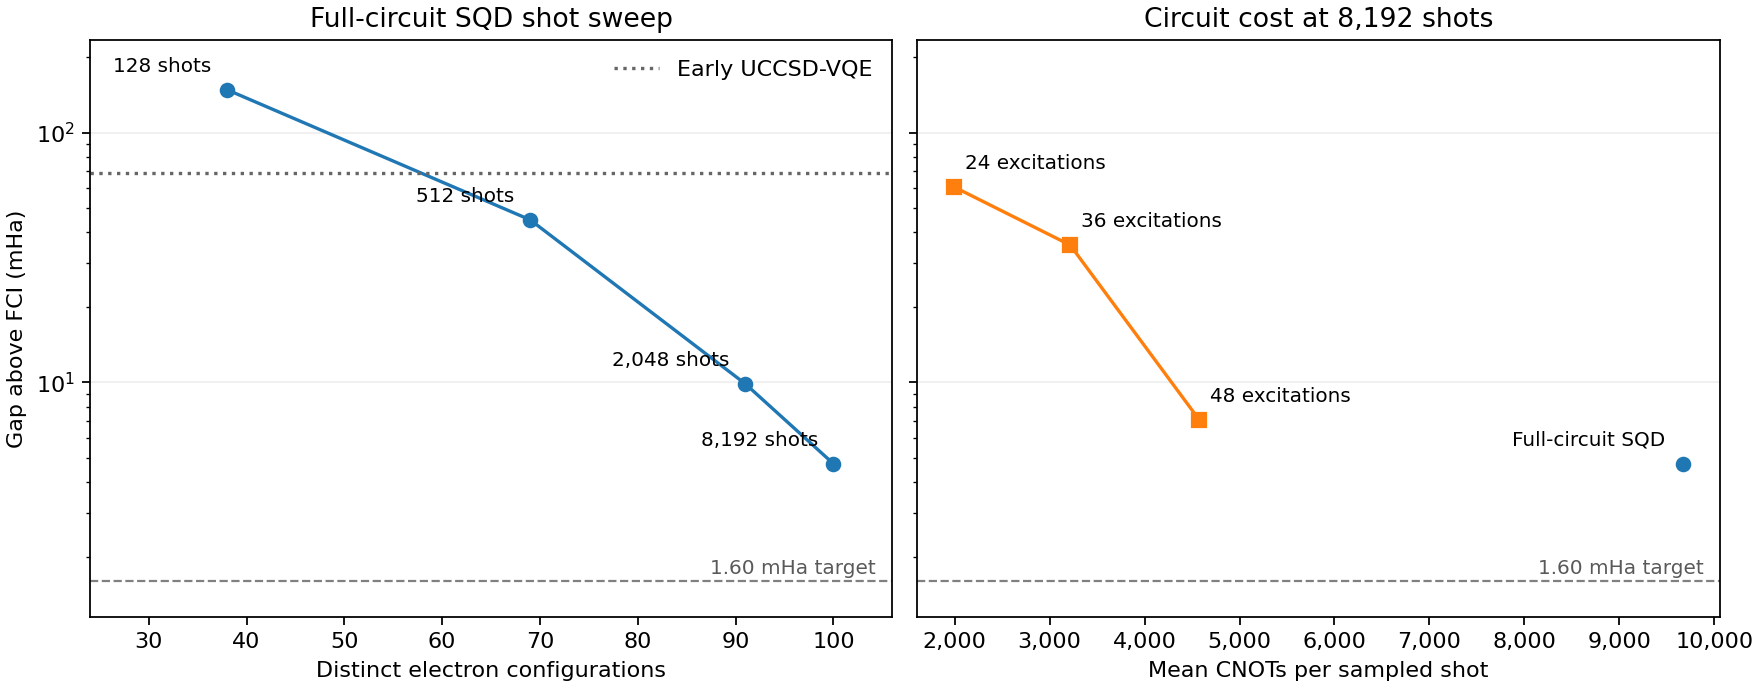

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import StrMethodFormatter

shots, dimensions, _, energies = zip(*h6_sqd_rows)
sampled_gaps = 1000 * (np.asarray(energies) - h6_exact_energy)
sizes, _, _, shallow_cx, shallow_gaps = zip(*h6_shallow_results)
early_gap = 1000 * (h6_pilot_energy - h6_exact_energy)

fig, (left, right) = plt.subplots(
    1, 2, figsize=(11, 4.3), sharey=True, layout="constrained"
)

# How the sampled subspace improves with more shots 
left.plot(dimensions, sampled_gaps, "o-", color="tab:blue")
for shot, dimension, gap in zip(shots, dimensions, sampled_gaps):
    left.annotate(
        f"{shot:,} shots", (dimension, gap), xytext=(-7, 8),
        textcoords="offset points", ha="right", fontsize=9,
    )
# Mark the error of the checkpoint that supplied the sampled state.
left.axhline(early_gap, color="0.4", linestyle=":", label="Early UCCSD-VQE")
left.set(
    xlabel="Distinct electron configurations",
    ylabel="Gap above FCI (mHa)",
    title="Full-circuit SQD shot sweep",
    xlim=(24, 106),
)
left.legend(loc="upper right", frameon=False)

# Accuracy versus circuit cost at equal shot count 
right.plot(shallow_cx, shallow_gaps, "s-", color="tab:orange")
for size, cx, gap in zip(sizes, shallow_cx, shallow_gaps):
    right.annotate(
        f"{size} excitations", (cx, gap), xytext=(5, 8),
        textcoords="offset points", fontsize=9,
    )
right.scatter(full_cx, sampled_gaps[-1], color="tab:blue", zorder=3)
right.annotate(
    "Full-circuit SQD", (full_cx, sampled_gaps[-1]), xytext=(-8, 8),
    textcoords="offset points", ha="right", fontsize=9,
)
right.set(xlabel="Mean CNOTs per sampled shot", title="Circuit cost at 8,192 shots")
right.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

for ax in (left, right):
    # Show the large gaps and the accuracy threshold on the same scale.
    ax.set_yscale("log")
    ax.set_ylim(1.15, 235)
    ax.axhline(1.60, color="0.5", linestyle="--", linewidth=1)
    ax.text(
        0.98, 1.65, "1.60 mHa target", transform=ax.get_yaxis_transform(),
        ha="right", va="bottom", fontsize=9, color="0.35",
    )
    ax.grid(axis="y", alpha=0.2)

plt.show()

The left panel shows where SQD first improves on the early UCCSD checkpoint in this shot sweep, at 512 shots. The right panel shows that retaining more excitations improves the pooled estimate at the cost of more CNOTs. All plotted points stay above 1.60 mHa.

The table records energy error and two separate costs. **VQE energy
evaluations** count optimisation work. **CNOTs per preparation** measure
compiled circuit size. For pooled samplers, we average the CNOT count
over the shots assigned to each circuit.

### Tabulate accuracy and resource measures

Put the gaps, determinant counts, VQE evaluations and gate counts side by side. The full-circuit SQD row includes the checkpoint training it reuses. The MP2 rows use classically derived angles, and the classical selection controls have no circuit-preparation count.

In [17]:
from IPython.display import Markdown, display

early_cx = h6_circuit.count_ops().get("cx", 0)
converged_cx = final_circuit.count_ops().get("cx", 0)

rows = [
    ("Early UCCSD-VQE", early_gap, None, len(h6_vqe_trace), early_cx),
    ("Converged UCCSD-VQE", h6_long_gap, None, h6_long_result.nfev, converged_cx),
    # Credit full-circuit SQD with the training cost it reuses.
    ("Full-circuit SQD", sampled_gaps[-1], dimensions[-1], len(h6_vqe_trace), full_cx),
]
for size, determinants, _, cx, gap in h6_shallow_results:
    rows.append((f"SQD, {size} excitations", gap, determinants, 0, cx))

rows.append(("Uniform random, median", np.median(valid_gaps), dimensions[-1], 0, None))
for label, (determinants, _, energy) in h6_classical_controls.items():
    rows.append((f"Classical control, {label.lower()}",
                 1000 * (energy - h6_exact_energy), determinants, 0, None))

table = [
    "| Method | Gap (mHa) | Selected determinants | VQE evaluations | CNOTs per preparation |",
    "|---|---:|---:|---:|---:|",
]
for name, gap, determinants, evaluations, cx in rows:
    det_text = "—" if determinants is None else f"{determinants:,}"
    cx_text = "—" if cx is None else f"{cx:,.0f}"
    table.append(f"| {name} | {gap:.2f} | {det_text} | {evaluations:,} | {cx_text} |")

display(Markdown("\n".join(table)))

| Method | Gap (mHa) | Selected determinants | VQE evaluations | CNOTs per preparation |
|---|---:|---:|---:|---:|
| Early UCCSD-VQE | 69.25 | — | 236 | 9,672 |
| Converged UCCSD-VQE | 4.74 | — | 1,418 | 9,672 |
| Full-circuit SQD | 4.72 | 100 | 236 | 9,672 |
| SQD, 24 excitations | 60.65 | 54 | 0 | 1,992 |
| SQD, 36 excitations | 35.46 | 72 | 0 | 3,216 |
| SQD, 48 excitations | 7.07 | 91 | 0 | 4,576 |
| Uniform random, median | 785.59 | 100 | 0 | — |
| Classical control, match determinants | 8.12 | 100 | 0 | — |
| Classical control, match singlet dimension | 8.21 | 99 | 0 | — |

The table puts the main comparisons in one place. Full-circuit SQD improves substantially on the early checkpoint and the selected classical controls. The longer UCCSD run reaches nearly the same gap, and the 48-excitation sampler gives up some accuracy to reduce circuit size.

## Conclusion

For the linear $\mathrm{H}_6$ chain at 1.50 Å, full-circuit SQD reduced
the early UCCSD-VQE error from **69.25 to 4.72 mHa** using 100 of the
400 determinants. At 128 shots, SQD gave a worse energy than the early
checkpoint, showing that the sampled configurations matter.

Converged UCCSD-VQE reached **4.74 mHa** after **1,418 energy evaluations**,
essentially matching full-circuit SQD. The 48-excitation MP2 sampler
reached **7.07 mHa** with **4,576 CNOTs per shot**, compared with **9,672**
for full-circuit SQD. Its angles came from a classical calculation, so
it required zero VQE optimisation evaluations. This is the observed
accuracy–cost trade-off for one geometry on a noiseless simulator.
The best sampled energy remained above the 1.60 mHa error target.

# <b>Moving forward </b> <a id="move"></a>

Test whether this trade-off persists at other hydrogen-chain spacings
and for longer chains. Compare alternative samplers, such as
sample-based Krylov diagonalisation, at equal total shot counts.

# <b>Credits </b> <a id="credits"></a>

Based on Benjamin Tirado's *Ground-State Energy of a Molecule with VQE*,
BasQ Qiskit Fall Fest 2026. The starter text is licensed under
[CC BY 4.0](https://creativecommons.org/licenses/by/4.0/) and the code
under [Apache 2.0](https://www.apache.org/licenses/LICENSE-2.0).

## Limitations

- The main benchmark covers one $\mathrm{H}_6$ spacing, one minimal basis and ideal statevector sampling. The electronic energy errors are relative to that model's singlet FCI energy. The best $\mathrm{H}_6$ estimate has a gap of 4.72 mHa against the 1.60 mHa target.
- The four full-circuit shot budgets reuse prefixes of one seeded sample stream. They show how the estimate changes along that stream. Only the uniform-random control is repeated across 32 draws.
- The random control matches the raw determinant count. The Hamiltonian-guided comparison matches the determinant count and the singlet dimension in separate runs. The latter is a budgeted selected-configuration-interaction heuristic.
- The compiled gate counts and statevector timings describe this simulation. Actual hardware would add connectivity, routing and noise. The VQE evaluation counts exclude the shots and classical eigensolves that SQD uses, and the MP2 gate comparison excludes the classical calculation of its angles. These measurements support an accuracy and circuit-cost comparison for this setup.

## References

- B. Tirado, *Ground-State Energy of a Molecule with VQE*, tutorial notebook, BasQ Qiskit Fall Fest, 2026. The attribution and licensing terms are given in the original starter credits. [BasQ event recap](https://www.basquequantum.eus/en/news/qiskit-fall-fest-2026-brings-together-quantum-community-three-basque-cities)
- A. Kandala et al., *Hardware-efficient variational quantum eigensolver for small molecules and quantum magnets*, Nature (2017). [Paper](https://doi.org/10.1038/nature23879)
- J. Robledo-Moreno et al., *Chemistry beyond the scale of exact diagonalization on a quantum-centric supercomputer*, Science Advances (2025). [Paper](https://doi.org/10.1126/sciadv.adu9991)
- IBM Quantum, *Sample-based quantum diagonalization of a chemistry Hamiltonian*. The tutorial illustrates configuration recovery and the local unitary cluster Jastrow (LUCJ) ansatz, a trial circuit built from orbital rotations and occupation-dependent interactions. [SQD tutorial](https://quantum.cloud.ibm.com/docs/en/tutorials/sample-based-quantum-diagonalization)
- Qiskit Nature, *Ground state solvers*. [Documentation](https://qiskit-community.github.io/qiskit-nature/tutorials/03_ground_state_solvers.html)